
Taper ratio (lambda)           : 0.6486
Mean Aerodynamic Chord (MAC)   : 0.2619 m
Aerodynamic Center y-pos (y_ac): 0.8994 m
Aerodynamic Center x-pos (x_ac): 0.2694 m



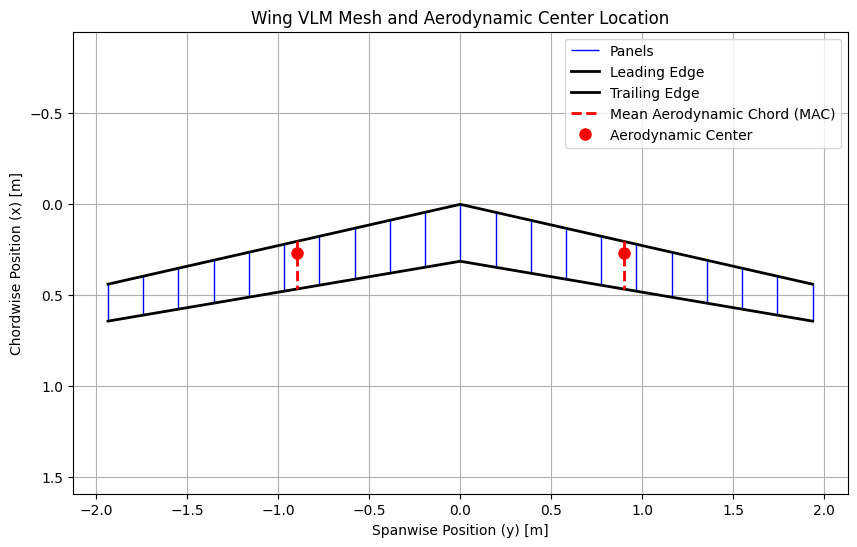

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ================= Wing Geometry & Discretization Parameters =================
b = 3.873               # Wingspan [m]
c_r = 0.313             # Root chord [m]
c_t = 0.203             # Tip chord [m]
Ny_semi = 10            # Number of semi-span panels
Ny = 2 * Ny_semi        # Total spanwise panels
S = 1.0                 # Wing planform area [m^2]
Lambda_c4_deg = 12.0    # Quarter-chord sweep angle [deg]

Lambda_c4_rad = np.radians(Lambda_c4_deg)

# ================= Geometric Calculations =================
# Taper ratio (lambda = c_t / c_r)
taper_ratio = c_t / c_r

# Mean Aerodynamic Chord (MAC) calculation
MAC = (2 / 3) * c_r * ((1 + taper_ratio + taper_ratio**2) / (1 + taper_ratio))

# Spanwise location of the Aerodynamic Center
y_ac = (b / 6) * ((1 + 2 * taper_ratio) / (1 + taper_ratio))

# Tangent of the leading and trailing edge sweep angles
tan_LE = np.tan(Lambda_c4_rad) + (0.25 * (c_r - c_t) / (b / 2))
tan_TE = np.tan(Lambda_c4_rad) - (0.75 * (c_r - c_t) / (b / 2))

# Chordwise location of the Aerodynamic Center
x_ac = y_ac * tan_LE + 0.25 * MAC

# ================= Console Output =================
print("\n" + "=" * 50)
print(f"Taper ratio (lambda)           : {taper_ratio:.4f}")
print(f"Mean Aerodynamic Chord (MAC)   : {MAC:.4f} m")
print(f"Aerodynamic Center y-pos (y_ac): {y_ac:.4f} m")
print(f"Aerodynamic Center x-pos (x_ac): {x_ac:.4f} m")
print("=" * 50 + "\n")

# ================= Spanwise Discretization =================
# Define panel boundaries along the wingspan
y = np.linspace(-b / 2, b / 2, 2 * Ny_semi + 1)

# Calculate Leading and Trailing Edge x-coordinates at panel boundaries
x_LE = np.abs(y) * tan_LE
x_TE = c_r + np.abs(y) * tan_TE

# ================= Plotting =================
plt.figure(figsize=(10, 6))

# Plot panels (vertical lines)
plt.vlines(x=y, ymin=x_LE, ymax=x_TE, colors='b', linewidth=1, label='Panels')

# Plot wing contour
plt.plot(y, x_LE, 'k-', linewidth=2, label='Leading Edge')
plt.plot(y, x_TE, 'k-', linewidth=2, label='Trailing Edge')

# Plot Mean Aerodynamic Chord (MAC) location
x_MAC_LE = y_ac * tan_LE
plt.vlines(x=[-y_ac, y_ac], ymin=x_MAC_LE, ymax=x_MAC_LE + MAC, colors='r', linestyles='dashed', linewidth=2, label='Mean Aerodynamic Chord (MAC)')

# Plot Aerodynamic Center
plt.plot([-y_ac, y_ac], [x_ac, x_ac], 'ro', markersize=8, label='Aerodynamic Center')

plt.gca().invert_yaxis()
plt.axis('equal')
plt.title("Wing VLM Mesh and Aerodynamic Center Location")
plt.xlabel("Spanwise Position (y) [m]")
plt.ylabel("Chordwise Position (x) [m]")

# Avoid duplicate legends
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())

plt.grid(True)
plt.show()

Panel    | y [m]      | Cl(-12°) | Cl( -6°) | Cl(  0°) | Cl(  6°) | Cl( 12°)
-------------------------------------------------------------------------------------
1        | -1.840     |   -0.997 |   -0.546 |   -0.094 |    0.358 |    0.810
2        | -1.646     |   -1.161 |   -0.619 |   -0.077 |    0.465 |    1.007
3        | -1.452     |   -1.186 |   -0.614 |   -0.041 |    0.531 |    1.103
4        | -1.259     |   -1.169 |   -0.585 |   -0.001 |    0.583 |    1.167
5        | -1.065     |   -1.135 |   -0.547 |    0.040 |    0.628 |    1.216
6        | -0.871     |   -1.092 |   -0.505 |    0.081 |    0.667 |    1.254
7        | -0.678     |   -1.044 |   -0.462 |    0.119 |    0.701 |    1.283
8        | -0.484     |   -0.993 |   -0.420 |    0.154 |    0.727 |    1.300
9        | -0.290     |   -0.939 |   -0.379 |    0.181 |    0.741 |    1.302
10       | -0.097     |   -0.881 |   -0.342 |    0.198 |    0.737 |    1.277
11       | 0.097      |   -0.881 |   -0.342 |    0.198 |    0.737 |

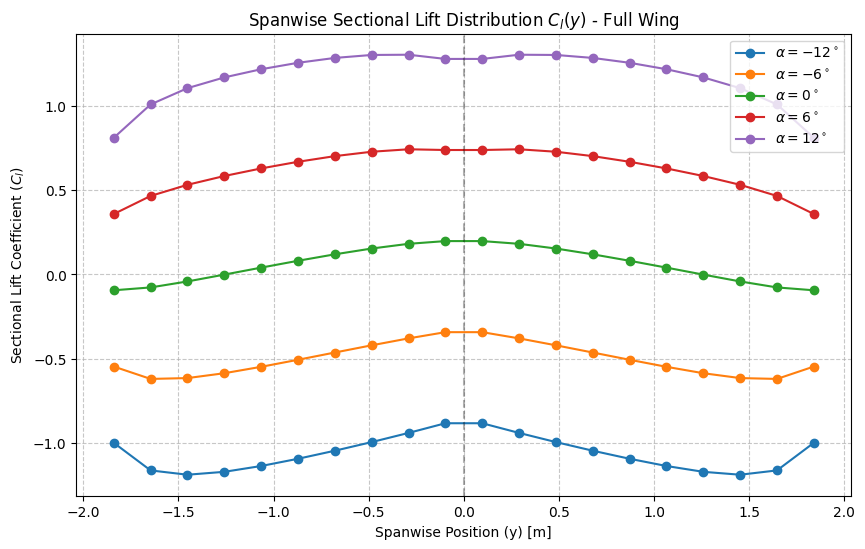

In [ ]:
# ================= Spanwise Nodes and Control Points =================
# Define panel boundaries and their midpoints
y_panels = np.linspace(-b / 2, b / 2, Ny + 1)
y_mid = (y_panels[:-1] + y_panels[1:]) / 2.0

# Chord distribution at control points and panel boundary nodes
c_mid = c_r - (c_r - c_t) * np.abs(y_mid) / (b / 2)
c_nodes = c_r - (c_r - c_t) * np.abs(y_panels) / (b / 2)

# Quarter-chord line (bound vortex line) and 3/4-chord line (collocation points)
x_c4_nodes = np.abs(y_panels) * tan_LE + 0.25 * c_nodes
x_ctrl = np.abs(y_mid) * tan_LE + 0.75 * c_mid

# Aerodynamic twist (geometric washout: -5 deg at tip) and NACA camber slope at 3/4 chord
local_twist = np.radians(-5.0 * np.abs(y_mid) / (b / 2))
dyc_dx_34 = (2 * 0.03 / (1 - 0.20)**2) * (0.20 - 0.75)

# ================= Biot-Savart Aerodynamic Influence Coefficient =================
def calc_a_ij(xc, yc, x1, y1, x2, y2):
    """
    Computes the normal velocity induced at a collocation point (xc, yc)
    by a horseshoe vortex bound between (x1, y1) and (x2, y2).
    """
    a, b_dist = xc - x1, yc - y1
    c, d_dist = xc - x2, yc - y2
    e, f = np.sqrt(a**2 + b_dist**2), np.sqrt(c**2 + d_dist**2)
    g, h = x2 - x1, y2 - y1

    den_k = a * d_dist - c * b_dist
    k = (g * a + h * b_dist) / e - (g * c + h * d_dist) / f
    k = k / den_k if abs(den_k) > 1e-9 else 0.0

    l = 0.0
    if abs(b_dist) > 1e-9 and abs(d_dist) > 1e-9:
        l = -(1 / b_dist) * (1 + a / e) + (1 / d_dist) * (1 + c / f)

    return (1 / (4 * np.pi)) * (k + l)

# ================= Aerodynamic Influence Coefficient Matrix (AIC) =================
# Assemble the influence matrix representing the downwash induced by all panels
A_mat = np.zeros((Ny, Ny))
for i in range(Ny):
    for j in range(Ny):
        A_mat[i, j] = calc_a_ij(x_ctrl[i], y_mid[i],
                                x_c4_nodes[j], y_panels[j],
                                x_c4_nodes[j+1], y_panels[j+1])

# ================= Boundary Conditions (RHS) & Linear Solver =================
alphas_deg = np.array([-12, -6, 0, 6, 12])
alphas_rad = np.radians(alphas_deg)

# RHS vector: downwash condition enforcing flow tangency at collocation points
B_mat = -(alphas_rad[np.newaxis, :] + local_twist[:, np.newaxis] - dyc_dx_34)

# Circulation normalized by freestream velocity (Gamma / U_inf)
Gamma_Uinf_matrix = np.linalg.solve(A_mat, B_mat)

# Sectional lift coefficient (Kutta-Joukowski theorem: Cl = 2 * Gamma / (U_inf * c))
cl_results = 2 * Gamma_Uinf_matrix / c_mid[:, np.newaxis]

# ================= Tabulated Results =================
header = f"{'Panel':<8} | {'y [m]':<10} | " + " | ".join([f"Cl({a:>3}°)" for a in alphas_deg])
print(header)
print("-" * 85)

for i in range(Ny):
    cl_values = " | ".join([f"{cl_results[i, j]:>8.3f}" for j in range(len(alphas_deg))])
    print(f"{i + 1:<8} | {y_mid[i]:<10.3f} | {cl_values}")
print("=" * 85)

# ================= Plotting =================
plt.figure(figsize=(10, 6))
for idx, a_deg in enumerate(alphas_deg):
    plt.plot(y_mid, cl_results[:, idx], '-o', label=f'$\\alpha = {a_deg}^\\circ$')

plt.title("Spanwise Sectional Lift Distribution $C_l(y)$ - Full Wing")
plt.xlabel("Spanwise Position (y) [m]")
plt.ylabel("Sectional Lift Coefficient ($C_l$)")
plt.xlim(-b / 2 - 0.1, b / 2 + 0.1)
plt.axvline(0, color='black', linestyle='--', alpha=0.3)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()


                SECTION 4: GLOBAL LIFT PARAMETERS                
Parameter                           | Value      | Units
-----------------------------------------------------------------
Lift curve slope (CL_alpha)         | 5.342      | 1/rad
Lift curve slope (CL_alpha)         | 0.0932     | 1/deg
Lift at zero AoA (CL_0)             | 0.068      | Dimensionless
Zero-lift angle of attack (a_L=0)   | -0.73      | deg


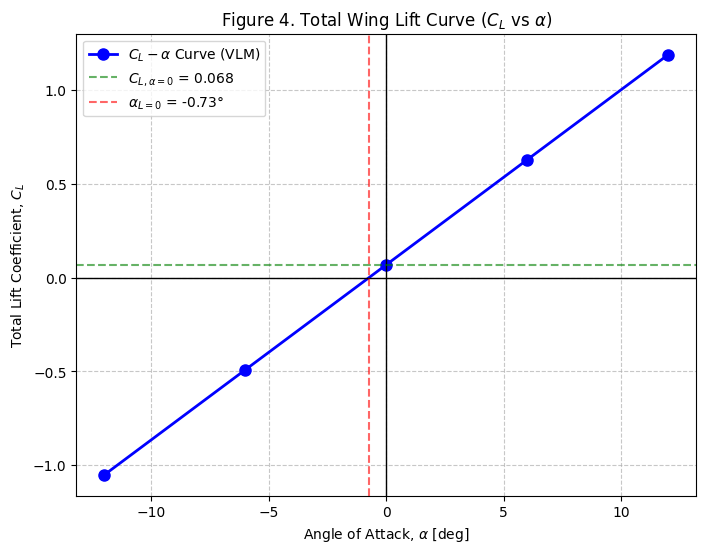

In [ ]:
# Compute panel width
dy = b / Ny

# Integrate spanwise sectional lift to obtain the total wing lift coefficient (CL)
CL_total = np.sum(cl_results * c_mid[:, np.newaxis] * dy, axis=0) / S

# Perform linear regression to extract lift curve slope and CL at zero AoA
coeffs = np.polyfit(alphas_deg, CL_total, 1)
CL_alpha_deg = coeffs[0]
CL_alpha_0 = coeffs[1]

# Convert slope to per radian and find the zero-lift angle of attack
CL_alpha_rad = CL_alpha_deg * np.degrees(1)
alpha_L0_deg = -CL_alpha_0 / CL_alpha_deg

print("\n" + "=" * 65)
print(f"{'SECTION 4: GLOBAL LIFT PARAMETERS':^65}")
print("=" * 65)
print(f"{'Parameter':<35} | {'Value':<10} | {'Units'}")
print("-" * 65)
print(f"{'Lift curve slope (CL_alpha)':<35} | {CL_alpha_rad:<10.3f} | 1/rad")
print(f"{'Lift curve slope (CL_alpha)':<35} | {CL_alpha_deg:<10.4f} | 1/deg")
print(f"{'Lift at zero AoA (CL_0)':<35} | {CL_alpha_0:<10.3f} | Dimensionless")
print(f"{'Zero-lift angle of attack (a_L=0)':<35} | {alpha_L0_deg:<10.2f} | deg")
print("=" * 65)

# ================= Plotting =================
plt.figure(figsize=(8, 6))
plt.plot(alphas_deg, CL_total, 'b-o', linewidth=2, markersize=8, label='$C_L - \\alpha$ Curve (VLM)')

# Plot reference axes
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)

# Plot CL_0 and alpha_L0 markers
plt.axhline(CL_alpha_0, color='green', linestyle='--', alpha=0.6, label=f'$C_{{L, \\alpha=0}}$ = {CL_alpha_0:.3f}')
plt.axvline(alpha_L0_deg, color='red', linestyle='--', alpha=0.6, label=f'$\\alpha_{{L=0}}$ = {alpha_L0_deg:.2f}°')

plt.title("Figure 4. Total Wing Lift Curve ($C_L$ vs $\\alpha$)")
plt.xlabel(r"Angle of Attack, $\alpha$ [deg]")
plt.ylabel(r"Total Lift Coefficient, $C_L$")
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()


   SECTION 5: BASIC AND ADDITIONAL LIFT DISTRIBUTIONS (Right Wing)    
Panel    | y [m]      | Cl_b (Basic)    | Cl_a (Additional)
----------------------------------------------------------------------
1        | 0.097      | 0.132           | 0.964          
2        | 0.290      | 0.113           | 1.001          
3        | 0.484      | 0.084           | 1.025          
4        | 0.678      | 0.048           | 1.040          
5        | 0.871      | 0.009           | 1.048          
6        | 1.065      | -0.031          | 1.050          
7        | 1.259      | -0.072          | 1.044          
8        | 1.452      | -0.111          | 1.023          
9        | 1.646      | -0.143          | 0.969          
10       | 1.840      | -0.149          | 0.807          


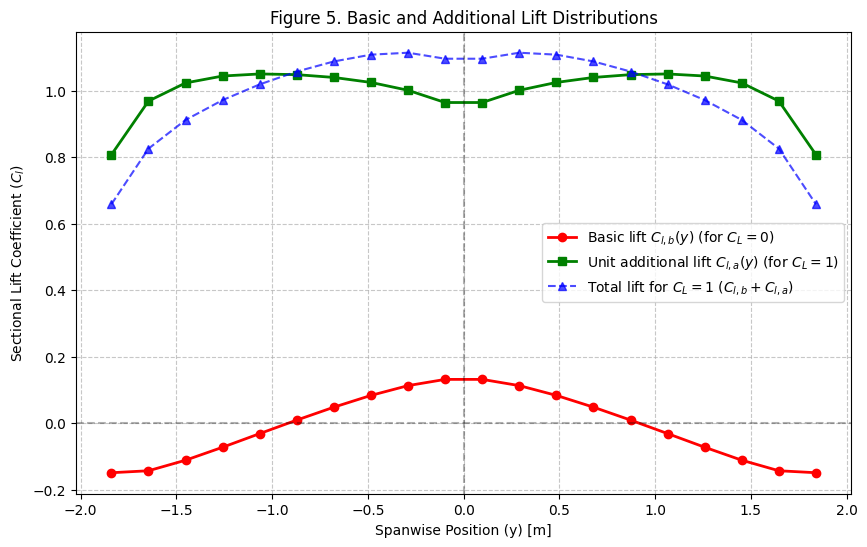

In [ ]:
# ================= Basic Lift Distribution (Cl_b) =================
# Lift distribution when total CL = 0, purely driven by twist and camber
alpha_L0_rad = np.radians(alpha_L0_deg)
RHS_b = -(alpha_L0_rad + local_twist - dyc_dx_34)
gamma_b = np.linalg.solve(A_mat, RHS_b)
Cl_b = 2 * gamma_b / c_mid

# ================= Additional Lift Distribution (Cl_a) =================
# Lift distribution contribution for a unitary angle of attack increase
RHS_a_temp = -np.ones(Ny)
gamma_a_temp = np.linalg.solve(A_mat, RHS_a_temp)
Cl_a_temp = 2 * gamma_a_temp / c_mid

# Normalize to a total CL of 1.0
CL_a_total_temp = np.sum(Cl_a_temp * c_mid * dy) / S
Cl_a = Cl_a_temp / CL_a_total_temp

print("\n" + "=" * 70)
print(f"{'SECTION 5: BASIC AND ADDITIONAL LIFT DISTRIBUTIONS (Right Wing)':^70}")
print("=" * 70)
print(f"{'Panel':<8} | {'y [m]':<10} | {'Cl_b (Basic)':<15} | {'Cl_a (Additional)':<15}")
print("-" * 70)

# Extract only the right wing panels for symmetry tabulation
right_wing_idx = np.where(y_mid >= 0)[0]

for n, i in enumerate(right_wing_idx):
    print(f"{n+1:<8} | {y_mid[i]:<10.3f} | {Cl_b[i]:<15.3f} | {Cl_a[i]:<15.3f}")
print("=" * 70)

# ================= Plotting =================
plt.figure(figsize=(10, 6))

plt.plot(y_mid, Cl_b, 'r-o', linewidth=2, label='Basic lift $C_{l,b}(y)$ (for $C_L=0$)')
plt.plot(y_mid, Cl_a, 'g-s', linewidth=2, label='Unit additional lift $C_{l,a}(y)$ (for $C_L=1$)')

# Total spanwise lift distribution for CL=1
Cl_total_CL1 = Cl_b + Cl_a * 1.0
plt.plot(y_mid, Cl_total_CL1, 'b--^', alpha=0.7, label='Total lift for $C_L=1$ ($C_{l,b} + C_{l,a}$)')

plt.title("Figure 5. Basic and Additional Lift Distributions")
plt.xlabel("Spanwise Position (y) [m]")
plt.ylabel(r"Sectional Lift Coefficient ($C_l$)")
plt.axvline(0, color='black', linestyle='--', alpha=0.3)
plt.axhline(0, color='black', linestyle='--', alpha=0.3)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()


            SECTION 6: LOCAL INDUCED DRAG COEFFICIENT cdi(y) (Right Wing)            
Panel    | y [m]      | cdi(-12°) | cdi( -6°) | cdi(  0°) | cdi(  6°) | cdi( 12°)
-------------------------------------------------------------------------------------
1        | 0.097      |   0.0061 |  -0.0006 |   0.0021 |   0.0143 |   0.0360
2        | 0.290      |   0.0114 |   0.0008 |   0.0014 |   0.0132 |   0.0362
3        | 0.484      |   0.0144 |   0.0020 |   0.0008 |   0.0108 |   0.0321
4        | 0.678      |   0.0170 |   0.0031 |   0.0003 |   0.0087 |   0.0281
5        | 0.871      |   0.0199 |   0.0044 |   0.0001 |   0.0069 |   0.0249
6        | 1.065      |   0.0235 |   0.0060 |  -0.0000 |   0.0055 |   0.0226
7        | 1.259      |   0.0286 |   0.0080 |   0.0000 |   0.0046 |   0.0218
8        | 1.452      |   0.0363 |   0.0109 |   0.0002 |   0.0041 |   0.0227
9        | 1.646      |   0.0487 |   0.0154 |   0.0006 |   0.0044 |   0.0266
10       | 1.840      |   0.0657 |   0.0213 |   0.00

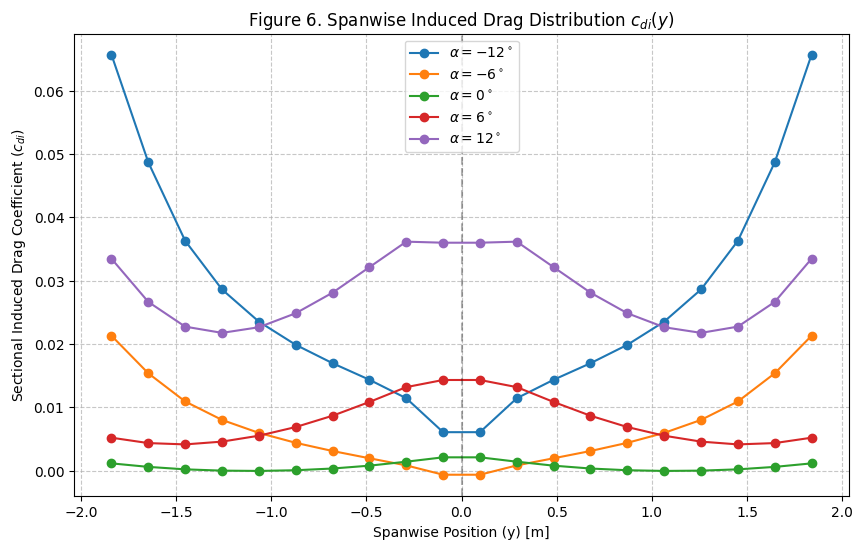

In [ ]:
# ================= Trefftz Plane Influence Matrix =================
term_left = 1.0 / (y_mid[:, np.newaxis] - y_panels[:-1])
term_right = 1.0 / (y_mid[:, np.newaxis] - y_panels[1:])
A_Trefftz = (1.0 / (2 * np.pi)) * (term_left - term_right)

# ================= Induced Downwash and Induced Drag =================
gamma_matrix = cl_results * (c_mid[:, np.newaxis] / 2.0)

w_Trefftz_matrix = A_Trefftz @ gamma_matrix
alpha_i_matrix = w_Trefftz_matrix / 2.0
cdi_results = cl_results * alpha_i_matrix
CDi_total = np.sum(cdi_results * c_mid[:, np.newaxis] * dy, axis=0) / S

# ================= Tabulated Results =================
print("\n" + "=" * 85)
print(f"{'SECTION 6: LOCAL INDUCED DRAG COEFFICIENT cdi(y) (Right Wing)':^85}")
print("=" * 85)
header_cdi = f"{'Panel':<8} | {'y [m]':<10} | " + " | ".join([f"cdi({a:>3}°)" for a in alphas_deg])
print(header_cdi)
print("-" * 85)

right_wing_idx = np.where(y_mid >= 0)[0]
for n, i in enumerate(right_wing_idx):
    cdi_values = " | ".join([f"{cdi_results[i, j]:>8.4f}" for j in range(len(alphas_deg))])
    print(f"{n+1:<8} | {y_mid[i]:<10.3f} | {cdi_values}")
print("=" * 85)

print("\n" + "=" * 50)
print(f"{'TOTAL WING INDUCED DRAG (CDi)':^50}")
print("=" * 50)
print(f"{'Angle of Attack':<20} | {'Total CDi'}")
print("-" * 50)
for idx, a_deg in enumerate(alphas_deg):
    print(f"{a_deg:>10}°          | {CDi_total[idx]:.4f}")
print("=" * 50)

# ================= Plotting =================
plt.figure(figsize=(10, 6))
for idx, a_deg in enumerate(alphas_deg):
    plt.plot(y_mid, cdi_results[:, idx], '-o', label=f'$\\alpha = {a_deg}^\\circ$')

plt.title("Figure 6. Spanwise Induced Drag Distribution $c_{di}(y)$")
plt.xlabel("Spanwise Position (y) [m]")
plt.ylabel(r"Sectional Induced Drag Coefficient ($c_{di}$)")
plt.xlim(-b / 2 - 0.1, b / 2 + 0.1)
plt.axvline(0, color='black', linestyle='--', alpha=0.3)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()


             SECTION 7: PITCHING MOMENT COEFFICIENTS             
Angle (°)       | CM_0y (Y-Axis)       | CM_ac (Aero Center)
-----------------------------------------------------------------
       -12°    |           1.115      |           0.034
        -6°    |           0.545      |           0.040
         0°    |          -0.026      |           0.045
         6°    |          -0.596      |           0.050
        12°    |          -1.166      |           0.055


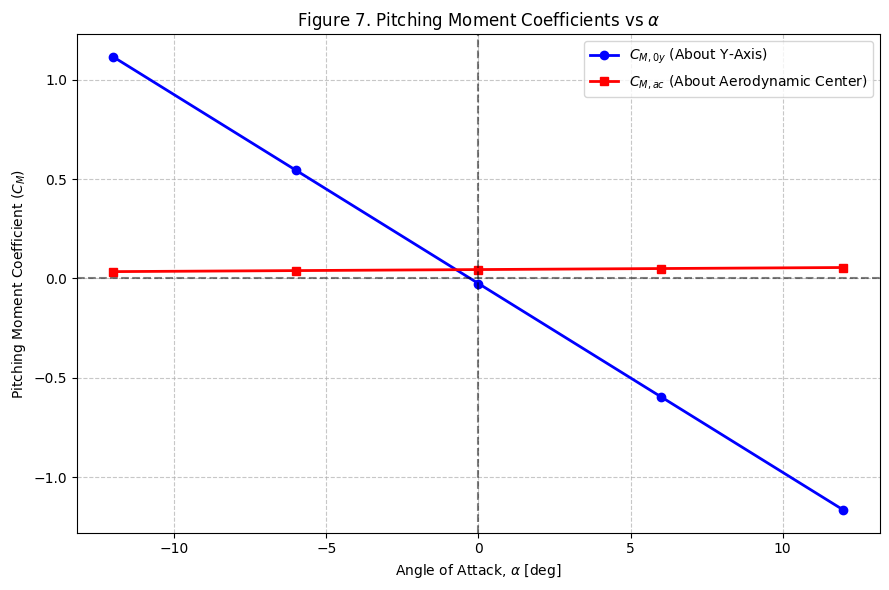

In [ ]:
# Use x_ca if x_ac was not previously defined in the workspace
if 'x_ac' not in locals() and 'x_ca' in locals():
    x_ac = x_ca

# Quarter-chord line x-coordinates evaluated at panel midpoints
x_c4_mid = np.abs(y_mid) * tan_LE + 0.25 * c_mid

# Compute pitching moment about the coordinate origin (Y-axis)
CM_0y_total = np.sum(-cl_results * (c_mid * x_c4_mid)[:, np.newaxis] * dy, axis=0) / (S * MAC)

# Translate the pitching moment to the calculated Aerodynamic Center
CM_ac_total = CM_0y_total + CL_total * (x_ac / MAC)

print("\n" + "=" * 65)
print(f"{'SECTION 7: PITCHING MOMENT COEFFICIENTS':^65}")
print("=" * 65)
print(f"{'Angle (°)':<15} | {'CM_0y (Y-Axis)':<20} | {'CM_ac (Aero Center)'}")
print("-" * 65)

for idx, a_deg in enumerate(alphas_deg):
    print(f"{a_deg:>10}°    | {CM_0y_total[idx]:>15.3f}      | {CM_ac_total[idx]:>15.3f}")
print("=" * 65)

# ================= Plotting =================
plt.figure(figsize=(9, 6))

plt.plot(alphas_deg, CM_0y_total, 'b-o', linewidth=2, label='$C_{M, 0y}$ (About Y-Axis)')
plt.plot(alphas_deg, CM_ac_total, 'r-s', linewidth=2, label='$C_{M, ac}$ (About Aerodynamic Center)')

plt.title("Figure 7. Pitching Moment Coefficients vs $\\alpha$")
plt.xlabel(r"Angle of Attack, $\alpha$ [deg]")
plt.ylabel(r"Pitching Moment Coefficient ($C_M$)")
plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.axvline(0, color='black', linestyle='--', alpha=0.5)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

Mounted at /content/drive
[OK] XFLR5 data parsed successfully.



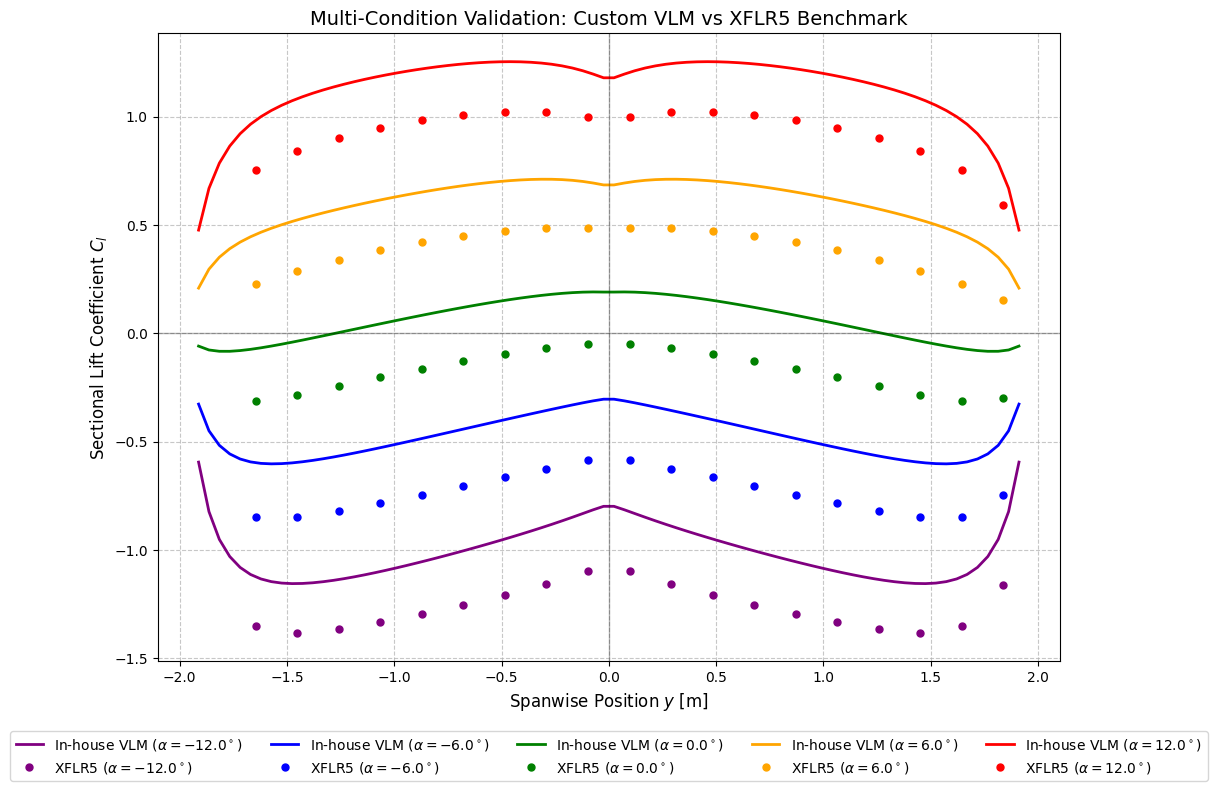

In [ ]:
import os
from google.colab import drive

# ================= Data Loading =================
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/Trabajo Alas/xflr 5 Cl.txt'

b = 3.873
c_r = 0.313
c_t = 0.203
tip_twist = -5.0
sweep_LE_deg = 20.0
tan_LE = np.tan(np.radians(sweep_LE_deg))
validation_alphas = [-12.0, -6.0, 0.0, 6.0, 12.0]

try:
    # Parse XFLR5 benchmark data
    xflr5_data = np.loadtxt(file_path, skiprows=1)
    xflr5_y = xflr5_data[:, 0]

    # Map validation angles to specific data columns
    xflr5_cl = {
        -12.0: xflr5_data[:, 1],
         -6.0: xflr5_data[:, 3],
          0.0: xflr5_data[:, 5],
          6.0: xflr5_data[:, 7],
         12.0: xflr5_data[:, 9]
    }
    print("[OK] XFLR5 data parsed successfully.\n")
except Exception as e:
    print(f"[ERROR] Problem reading file: {e}")

# ================= VLM Solver Function =================
def solve_vlm(Ny, alpha_deg):
    """
    Standalone function to compute the spanwise lift distribution
    for a given number of panels and angle of attack.
    """
    alpha_rad = np.radians(alpha_deg)
    y_panels = np.linspace(-b / 2, b / 2, Ny + 1)
    y_mid = (y_panels[:-1] + y_panels[1:]) / 2.0

    c_mid = c_r - (c_r - c_t) * np.abs(y_mid) / (b / 2)
    c_nodes = c_r - (c_r - c_t) * np.abs(y_panels) / (b / 2)
    x_c4_nodes = np.abs(y_panels) * tan_LE + 0.25 * c_nodes
    x_ctrl = np.abs(y_mid) * tan_LE + 0.75 * c_mid

    local_twist = np.radians(tip_twist * np.abs(y_mid) / (b / 2))
    dyc_dx_34 = (2 * 0.03 / (1 - 0.20)**2) * (0.20 - 0.75)

    A_mat = np.zeros((Ny, Ny))
    for i in range(Ny):
        for j in range(Ny):
            a, b_dist = x_ctrl[i] - x_c4_nodes[j], y_mid[i] - y_panels[j]
            c_dist, d_dist = x_ctrl[i] - x_c4_nodes[j+1], y_mid[i] - y_panels[j+1]
            e, f = np.sqrt(a**2 + b_dist**2), np.sqrt(c_dist**2 + d_dist**2)
            g, h = x_c4_nodes[j+1] - x_c4_nodes[j], y_panels[j+1] - y_panels[j]

            den_k = a * d_dist - c_dist * b_dist
            k = ((g * a + h * b_dist) / e - (g * c_dist + h * d_dist) / f) / den_k if abs(den_k) > 1e-9 else 0.0
            l = -(1 / b_dist) * (1 + a / e) + (1 / d_dist) * (1 + c_dist / f) if (abs(b_dist) > 1e-9 and abs(d_dist) > 1e-9) else 0.0
            A_mat[i, j] = (1 / (4 * np.pi)) * (k + l)

    RHS = -(alpha_rad + local_twist - dyc_dx_34)
    gamma_v = np.linalg.solve(A_mat, RHS)
    return y_mid, 2 * gamma_v / c_mid

# ================= Plotting Comparison =================
plt.figure(figsize=(12, 8))
colors = {-12.0: 'purple', -6.0: 'blue', 0.0: 'green', 6.0: 'orange', 12.0: 'red'}

for a_deg in validation_alphas:
    # Run custom VLM with high panel density (Ny=80) for smooth validation
    y_vlm, cl_vlm = solve_vlm(80, a_deg)

    plt.plot(y_vlm, cl_vlm, color=colors[a_deg], linestyle='-', linewidth=2,
             label=f'In-house VLM ($\\alpha={a_deg}^\\circ$)')

    if 'xflr5_cl' in locals():
        plt.plot(xflr5_y, xflr5_cl[a_deg], color=colors[a_deg], marker='o',
                 linestyle='', markersize=5, label=f'XFLR5 ($\\alpha={a_deg}^\\circ$)')

plt.title('Multi-Condition Validation: Custom VLM vs XFLR5 Benchmark', fontsize=14)
plt.xlabel(r'Spanwise Position $y$ [m]', fontsize=12)
plt.ylabel(r'Sectional Lift Coefficient $C_l$', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.axhline(0, color='black', linewidth=1, alpha=0.3)
plt.axvline(0, color='black', linewidth=1, alpha=0.3)

# Anchor legend below the plot to avoid cluttering data lines
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=5)
plt.tight_layout()
plt.show()


        GRID CONVERGENCE STUDY: N_y vs TIME vs TOTAL C_L         
Panels (Ny)     | Time [s]             | Total CL       
-----------------------------------------------------------------
10              | 0.0016               | 0.61812
20              | 0.0094               | 0.61249
40              | 0.0325               | 0.60778
80              | 0.0673               | 0.60521
160             | 0.2630               | 0.60393
320             | 1.0541               | 0.60329


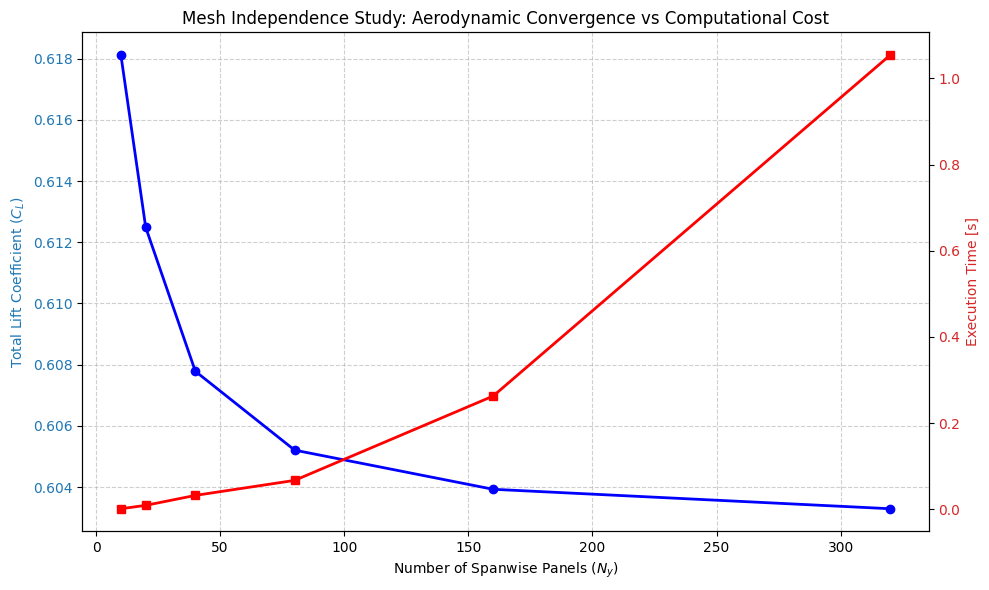

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt

b = 3.873
c_r = 0.313
c_t = 0.203
tip_twist = -5.0
sweep_LE_deg = 20.0
tan_LE = np.tan(np.radians(sweep_LE_deg))
alpha_rad = np.radians(6.0)

# Array of panel densities to test for mesh convergence
test_panels = [10, 20, 40, 80, 160, 320]

execution_times = []
CL_totals = []

print("\n" + "=" * 65)
print(f"{'GRID CONVERGENCE STUDY: N_y vs TIME vs TOTAL C_L':^65}")
print("=" * 65)
print(f"{'Panels (Ny)':<15} | {'Time [s]':<20} | {'Total CL':<15}")
print("-" * 65)

for Ny in test_panels:
    t_start = time.time()

    # Re-discretize the wing with the current panel count
    y_panels = np.linspace(-b / 2, b / 2, Ny + 1)
    y_mid = (y_panels[:-1] + y_panels[1:]) / 2.0

    c_mid = c_r - (c_r - c_t) * np.abs(y_mid) / (b / 2)
    c_nodes = c_r - (c_r - c_t) * np.abs(y_panels) / (b / 2)
    x_c4_nodes = np.abs(y_panels) * tan_LE + 0.25 * c_nodes
    x_ctrl = np.abs(y_mid) * tan_LE + 0.75 * c_mid

    local_twist = np.radians(tip_twist * np.abs(y_mid) / (b / 2))
    dyc_dx_34 = (2 * 0.03 / (1 - 0.20)**2) * (0.20 - 0.75)

    # Re-calculate the Aerodynamic Influence Matrix
    A_mat = np.zeros((Ny, Ny))
    for i in range(Ny):
        for j in range(Ny):
            a, b_dist = x_ctrl[i] - x_c4_nodes[j], y_mid[i] - y_panels[j]
            c_dist, d_dist = x_ctrl[i] - x_c4_nodes[j+1], y_mid[i] - y_panels[j+1]
            e, f = np.sqrt(a**2 + b_dist**2), np.sqrt(c_dist**2 + d_dist**2)
            g, h = x_c4_nodes[j+1] - x_c4_nodes[j], y_panels[j+1] - y_panels[j]

            den_k = a * d_dist - c_dist * b_dist
            k = ((g * a + h * b_dist) / e - (g * c_dist + h * d_dist) / f) / den_k if abs(den_k) > 1e-9 else 0.0
            l = -(1 / b_dist) * (1 + a / e) + (1 / d_dist) * (1 + c_dist / f) if (abs(b_dist) > 1e-9 and abs(d_dist) > 1e-9) else 0.0
            A_mat[i, j] = (1 / (4 * np.pi)) * (k + l)

    RHS = -(alpha_rad + local_twist - dyc_dx_34)
    gamma_v = np.linalg.solve(A_mat, RHS)
    cl_local = 2 * gamma_v / c_mid

    # Calculate total lift using an array of local panel widths (dy)
    dy_array = np.diff(y_panels)
    CL_total = np.sum(cl_local * c_mid * dy_array) / 1.0

    # Record solver execution time
    t_end = time.time()
    elapsed_time = t_end - t_start

    execution_times.append(elapsed_time)
    CL_totals.append(CL_total)

    print(f"{Ny:<15} | {elapsed_time:<20.4f} | {CL_total:.5f}")

# ================= Double-Axis Plotting =================
fig, ax1 = plt.subplots(figsize=(10, 6))

# Primary Y-Axis: Aerodynamic convergence (CL)
color1 = 'tab:blue'
ax1.set_xlabel(r'Number of Spanwise Panels ($N_y$)')
ax1.set_ylabel(r'Total Lift Coefficient ($C_L$)', color=color1)
ax1.plot(test_panels, CL_totals, 'b-o', linewidth=2, label=r'$C_L$ Convergence')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, linestyle='--', alpha=0.6)

# Secondary Y-Axis: Computational cost (Time)
ax2 = ax1.twinx()
color2 = 'tab:red'
ax2.set_ylabel('Execution Time [s]', color=color2)
ax2.plot(test_panels, execution_times, 'r-s', linewidth=2, label='Computational Cost')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('Mesh Independence Study: Aerodynamic Convergence vs Computational Cost')
fig.tight_layout()
plt.show()

5D design space exploration completed in 46.47 seconds.

Found 1490 feasible configurations. TOP 5:

Rank  | NACA   | AR      | Sweep [°]   | Taper      | Twist [°]    | Stall Loc.  | Gradient   | Cost  
------------------------------------------------------------------------------------------------------
Op 1  | 4417   |    7.24 |     14.74   |     0.905  |       -9.00  |      15.0%  |     -0.201 |  1.064
Op 2  | 3217   |    6.21 |     16.84   |     0.905  |       -9.00  |      15.0%  |     -0.201 |  1.078
Op 3  | 4417   |    6.72 |     14.74   |     0.905  |       -9.00  |      15.0%  |     -0.206 |  1.081
Op 4  | 2412   |    6.21 |     12.63   |     0.811  |       -9.00  |      15.0%  |     -0.200 |  1.086
Op 5  | 4417   |    6.72 |     12.63   |     0.858  |       -9.00  |      15.0%  |     -0.202 |  1.088


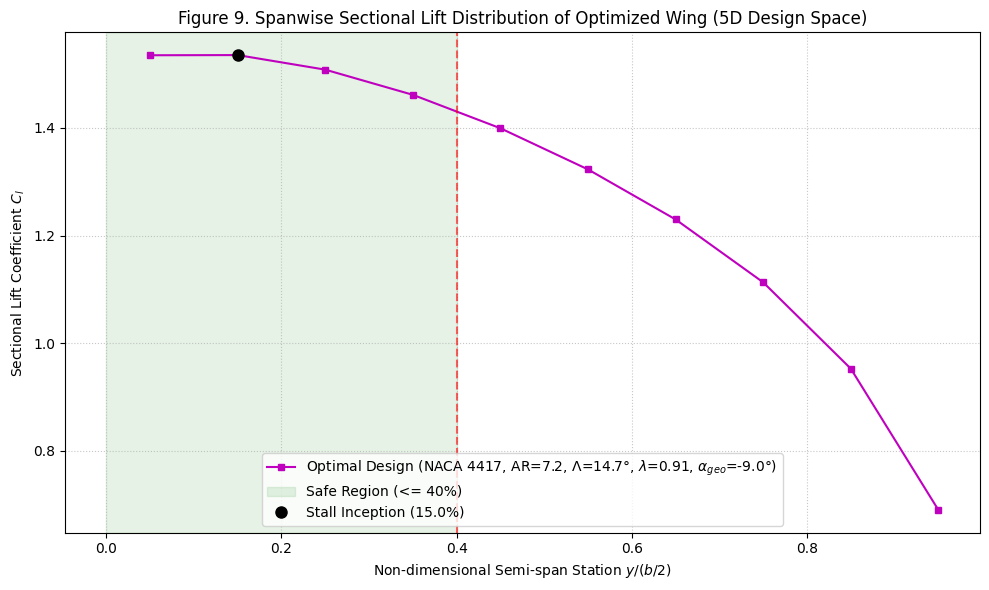

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt

# ================= Original Geometry & Constraints =================
S = 1.0
b_orig = 3.873
AR_orig = b_orig**2 / S
c_r = 0.313
taper_orig = 0.65
twist_orig = -5.0
sweep_orig = 20.0
Ny = 20
alpha_stall = 15.0

# ================= 5D Parameter Search Space =================
b_test = np.linspace(3.873, 2.0, 20)
sweeps_test = np.linspace(20.0, 0.0, 20)
tapers_test = np.linspace(0.1, 1.0, 20)
twists_test = np.linspace(0.0, -9.0, 5)
nacas_test = ['0012', '2412', '3217', '4417']

valid_solutions = []
t0 = time.time()

# ================= Optimization Loop =================
for b_curr in b_test:
    AR_curr = b_curr**2 / S
    y_panels = np.linspace(-b_curr / 2, b_curr / 2, Ny + 1)
    y_mid = (y_panels[:-1] + y_panels[1:]) / 2.0

    # Isolate right wing to evaluate stall inception cleanly
    right_wing_idx = np.where(y_mid >= 0)[0]
    y_right = y_mid[right_wing_idx]
    dy_val = b_curr / Ny

    for sweep in sweeps_test:
        tan_LE = np.tan(np.radians(sweep))

        for taper in tapers_test:
            c_t = c_r * taper
            c_mid = c_r - (c_r - c_t) * np.abs(y_mid) / (b_curr / 2)
            c_nodes = c_r - (c_r - c_t) * np.abs(y_panels) / (b_curr / 2)
            x_c4_nodes = np.abs(y_panels) * tan_LE + 0.25 * c_nodes
            x_ctrl = np.abs(y_mid) * tan_LE + 0.75 * c_mid

            # The AIC matrix is strictly a function of planform geometry (sweep, taper, span)
            A_mat = np.zeros((Ny, Ny))
            for i in range(Ny):
                for j in range(Ny):
                    a, b_dist = x_ctrl[i] - x_c4_nodes[j], y_mid[i] - y_panels[j]
                    c_dist, d_dist = x_ctrl[i] - x_c4_nodes[j+1], y_mid[i] - y_panels[j+1]
                    e, f = np.sqrt(a**2 + b_dist**2), np.sqrt(c_dist**2 + d_dist**2)
                    g, h = x_c4_nodes[j+1] - x_c4_nodes[j], y_panels[j+1] - y_panels[j]

                    den_k = a * d_dist - c_dist * b_dist
                    k = ((g * a + h * b_dist) / e - (g * c_dist + h * d_dist) / f) / den_k if abs(den_k) > 1e-9 else 0.0
                    l = -(1 / b_dist) * (1 + a / e) + (1 / d_dist) * (1 + c_dist / f) if (abs(b_dist) > 1e-9 and abs(d_dist) > 1e-9) else 0.0
                    A_mat[i, j] = (1 / (4 * np.pi)) * (k + l)

            for twist in twists_test:
                local_twist = np.radians(twist * np.abs(y_mid) / (b_curr / 2))

                for naca in nacas_test:
                    # Extract 4-digit NACA geometry parameters (camber & max camber position)
                    m_camber = int(naca[0]) / 100.0
                    p_pos = int(naca[1]) / 10.0

                    if m_camber == 0:
                        dyc_dx_34 = 0.0  # Symmetrical airfoil
                    else:
                        dyc_dx_34 = (2 * m_camber / (1 - p_pos)**2) * (p_pos - 0.75)

                    RHS = -(np.radians(alpha_stall) + local_twist - dyc_dx_34)
                    gamma_v = np.linalg.solve(A_mat, RHS)
                    cl_local = 2 * gamma_v / c_mid

                    # ================= Stall Inception Analysis =================
                    cl_right = cl_local[right_wing_idx]
                    idx_stall = np.argmax(cl_right)
                    rel_pos = y_right[idx_stall] / (b_curr / 2)

                    # Compute spanwise lift gradient at stall location
                    gradient = (cl_right[idx_stall + 1] - cl_right[idx_stall]) / dy_val if idx_stall < len(cl_right) - 1 else 0.0

                    # Constraint: Root stall enforced (onset inboard of 40% semi-span)
                    if rel_pos <= 0.40 and gradient <= -0.20:
                        # Cost function: L2-norm penalty for deviating from the baseline design
                        penal_sweep = ((sweep - sweep_orig) / sweep_orig) ** 2 if sweep_orig != 0 else (sweep / 10)**2
                        penal_taper = ((taper - taper_orig) / taper_orig) ** 2
                        penal_twist = ((twist - twist_orig) / twist_orig) ** 2 if twist_orig != 0 else (twist / 10)**2
                        penal_ar = ((AR_curr - AR_orig) / AR_orig) ** 2

                        total_cost = np.sqrt(penal_sweep + penal_taper + penal_twist + penal_ar)

                        valid_solutions.append({
                            'naca': naca, 'b': b_curr, 'AR': AR_curr, 'sweep': sweep,
                            'taper': taper, 'twist': twist, 'cost': total_cost,
                            'rel_pos': rel_pos, 'gradient': gradient,
                            'y_opt': y_right, 'cl_opt': cl_right, 'idx_stall': idx_stall
                        })

t1 = time.time()
print(f"5D design space exploration completed in {t1 - t0:.2f} seconds.")

# ================= Post-Processing and Output =================
if len(valid_solutions) > 0:
    sorted_solutions = sorted(valid_solutions, key=lambda x: x['cost'])
    top_5 = sorted_solutions[:5]

    print(f"\nFound {len(valid_solutions)} feasible configurations. TOP 5:\n")
    header = f"{'Rank':<5} | {'NACA':<6} | {'AR':<7} | {'Sweep [°]':<11} | {'Taper':<10} | {'Twist [°]':<12} | {'Stall Loc.':<11} | {'Gradient':<10} | {'Cost':<6}"
    print(header)
    print("-" * len(header))

    for i, sol in enumerate(top_5):
        print(f"Op {i+1:<2} | {sol['naca']:<6} | {sol['AR']:>7.2f} | {sol['sweep']:>9.2f}   | {sol['taper']:>9.3f}  | {sol['twist']:>11.2f}  | {sol['rel_pos']*100:>9.1f}%  | {sol['gradient']:>10.3f} | {sol['cost']:>6.3f}")
    print("=" * len(header))

    # Plot optimal solution
    best = top_5[0]
    plt.figure(figsize=(10, 6))
    plt.plot(best['y_opt'] / (best['b'] / 2), best['cl_opt'], 'm-s', markersize=4, linewidth=1.5,
             label=rf"Optimal Design (NACA {best['naca']}, AR={best['AR']:.1f}, $\Lambda$={best['sweep']:.1f}°, $\lambda$={best['taper']:.2f}, $\alpha_{{geo}}$={best['twist']:.1f}°)")

    # Highlight root stall safety boundary
    plt.axvspan(0, 0.40, color='green', alpha=0.1, label='Safe Region (<= 40%)')
    plt.axvline(0.40, color='red', linestyle='--', alpha=0.6)

    # Mark maximum Cl location (stall inception)
    plt.plot(best['rel_pos'], best['cl_opt'][best['idx_stall']], 'ko', markersize=8, label=f"Stall Inception ({best['rel_pos']*100:.1f}%)")

    plt.title("Figure 9. Spanwise Sectional Lift Distribution of Optimized Wing (5D Design Space)", fontsize=12)
    plt.xlabel(r"Non-dimensional Semi-span Station $y / (b/2)$")
    plt.ylabel(r"Sectional Lift Coefficient $C_l$")
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc='lower center')
    plt.tight_layout()
    plt.show()

else:
    print("\n[X] Error: No feasible configurations satisfied the design constraints.")